<a href="https://colab.research.google.com/github/AlmasIffat/GRU/blob/main/GRUTemp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
import pandas as pd

# Upload CSV file
uploaded = files.upload()

Saving temperature.csv to temperature (1).csv


In [ ]:
import numpy as np

# Training data
X = np.array([1, 2, 3], dtype=float)
Y = np.array([2, 4, 6], dtype=float)

# Initialize weight
w = 0.5

# Learning rate
lr = 0.1

# Training loop
for epoch in range(10):

    # Forward propagation
    y_pred = w * X

    # Calculate loss
    loss = np.mean((y_pred - Y) ** 2)

    # Calculate gradient
    gradient = np.mean(2 * X * (y_pred - Y))

    # Update weight
    w = w - lr * gradient

    print(
        f"Epoch {epoch + 1}: "
        f"Loss = {loss:.6f}, "
        f"Weight = {w:.6f}"
    )

print("Final weight:", w)

Epoch 1: Loss = 10.500000, Weight = 1.900000
Epoch 2: Loss = 0.046667, Weight = 1.993333
Epoch 3: Loss = 0.000207, Weight = 1.999556
Epoch 4: Loss = 0.000001, Weight = 1.999970
Epoch 5: Loss = 0.000000, Weight = 1.999998
Epoch 6: Loss = 0.000000, Weight = 2.000000
Epoch 7: Loss = 0.000000, Weight = 2.000000
Epoch 8: Loss = 0.000000, Weight = 2.000000
Epoch 9: Loss = 0.000000, Weight = 2.000000
Epoch 10: Loss = 0.000000, Weight = 2.000000
Final weight: 1.9999999999973987


In [ ]:
import numpy as np

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

from imblearn.over_sampling import SMOTE
from collections import Counter

# 1. Create an imbalanced dataset
X, y = make_classification(
    n_samples=10000,
    n_features=10,
    n_informative=5,
    n_redundant=2,
    weights=[0.98, 0.02],
    random_state=42
)

print("Original distribution:", Counter(y))

# 2. Split the data BEFORE resampling
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# 3. Scale the features using training data only
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training distribution before SMOTE:",
      Counter(y_train))

# 4. Apply SMOTE ONLY to training data
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train,
    y_train
)

print("Training distribution after SMOTE:",
      Counter(y_train_balanced))

# 5. Train the model on balanced training data
model = LogisticRegression(max_iter=1000)

model.fit(X_train_balanced, y_train_balanced)

# 6. Evaluate on the original, untouched test data
y_pred = model.predict(X_test)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Original distribution: Counter({np.int64(0): 9754, np.int64(1): 246})
Training distribution before SMOTE: Counter({np.int64(0): 7803, np.int64(1): 197})
Training distribution after SMOTE: Counter({np.int64(0): 7803, np.int64(1): 7803})

Confusion Matrix:
[[1437  514]
 [  13   36]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.74      0.85      1951
           1       0.07      0.73      0.12        49

    accuracy                           0.74      2000
   macro avg       0.53      0.74      0.48      2000
weighted avg       0.97      0.74      0.83      2000



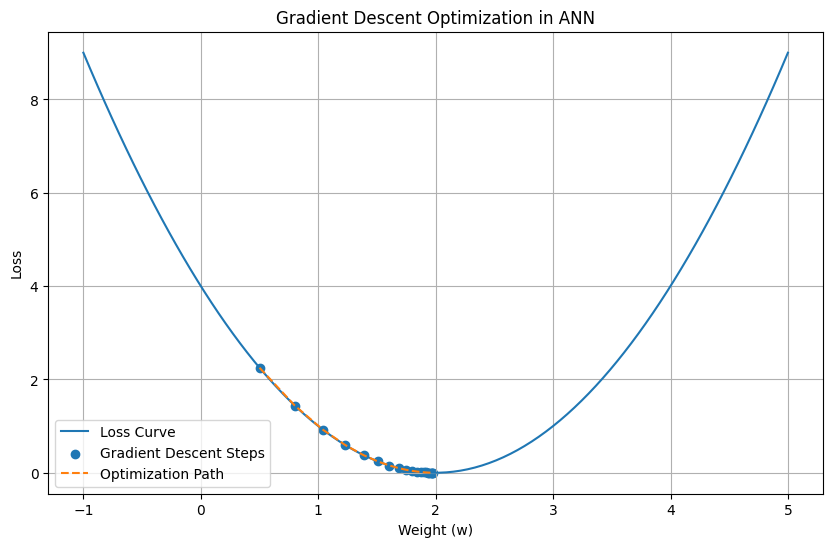

Final weight: 1.9827
Final loss: 0.000299


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Loss function
def loss(w):
    return (w - 2) ** 2

# Gradient of the loss function
def gradient(w):
    return 2 * (w - 2)

# Initialize parameters
w = 0.5
learning_rate = 0.1
epochs = 20

# Store values for plotting
weights = []
losses = []

# Gradient Descent
for epoch in range(epochs):
    weights.append(w)
    losses.append(loss(w))

    # Update weight
    w = w - learning_rate * gradient(w)

# Generate loss curve
w_values = np.linspace(-1, 5, 100)
loss_values = loss(w_values)

# Plot the curve
plt.figure(figsize=(10, 6))
plt.plot(w_values, loss_values, label="Loss Curve")
plt.scatter(weights, losses, label="Gradient Descent Steps")

# Connect optimization steps
plt.plot(weights, losses, linestyle="--", label="Optimization Path")

plt.xlabel("Weight (w)")
plt.ylabel("Loss")
plt.title("Gradient Descent Optimization in ANN")
plt.legend()
plt.grid(True)
plt.show()

print("Final weight:", round(w, 4))
print("Final loss:", round(loss(w), 6))

In [ ]:
# ==========================================
# 1. Import Libraries
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping


# ==========================================
# 2. Load Dataset
# ==========================================

df = pd.read_csv("temperature.csv")

print("Dataset Shape:", df.shape)
print("Available Columns:")
print(df.columns.tolist())


# ==========================================
# 3. Select Required Columns
# ==========================================

# Identify columns by ignoring extra spaces and encoding differences
df.columns = [
    str(col).strip().replace("Â", "")
    for col in df.columns
]

time_col = "Data Acquisition Time"

temperature_col = next(
    col for col in df.columns
    if "Air Temperature Telemetry Hourly" in col
)

df = df[[time_col, temperature_col]].copy()

df.columns = ["datetime", "temperature"]


# ==========================================
# 4. Clean Dataset
# ==========================================

df["datetime"] = pd.to_datetime(
    df["datetime"],
    errors="coerce"
)

df["temperature"] = pd.to_numeric(
    df["temperature"],
    errors="coerce"
)

df = df.dropna()

# Sort records chronologically
df = df.sort_values("datetime")

# Remove duplicate timestamps
df = df.drop_duplicates(
    subset=["datetime"],
    keep="last"
)

df = df.reset_index(drop=True)

# print("\nCleaned Data:")
# print(df.head())

# print("\nTotal Records:", len(df))


# ==========================================
# 5. Prepare Hourly Time Series
# ==========================================

# IMPORTANT:
# Use one station's data before this step if the
# CSV contains readings from multiple stations.

# Check whether timestamps are hourly
time_differences = df["datetime"].diff().dropna()

# print("\nMost Common Time Differences:")
# print(time_differences.value_counts().head())


# ==========================================
# 6. Scale Temperature Values
# ==========================================

temperature_values = df[["temperature"]].values

scaler = MinMaxScaler(feature_range=(0, 1))

scaled_data = scaler.fit_transform(temperature_values)


# ==========================================
# 7. Create Input Sequences
# ==========================================

# Use the previous 24 observations to predict
# the next observation.

timesteps = 24

X = []
y = []

for i in range(timesteps, len(scaled_data)):
    X.append(scaled_data[i - timesteps:i, 0])
    y.append(scaled_data[i, 0])

X = np.array(X)
y = np.array(y)
print(X)
# print(y)
# print(df)

Dataset Shape: (967, 9)
Available Columns:
['SlNo', 'Station', 'Agency', 'State LGD Code', 'State', 'District LGD Code', 'District', 'Data Acquisition Time', 'Air Temperature Telemetry Hourly (ºC)']
[[0.51020408 0.53061224 0.53571429 ... 0.65816327 0.6377551  0.63265306]
 [0.53061224 0.53571429 0.53061224 ... 0.6377551  0.63265306 0.04591837]
 [0.53571429 0.53061224 0.5255102  ... 0.63265306 0.04591837 0.04081633]
 ...
 [0.18877551 0.18877551 0.17346939 ... 0.19897959 0.18877551 0.19387755]
 [0.18877551 0.17346939 0.16836735 ... 0.18877551 0.19387755 0.18367347]
 [0.17346939 0.16836735 0.18877551 ... 0.19387755 0.18367347 0.17346939]]


/tmp/ipykernel_1896/3503692826.py:54: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["datetime"] = pd.to_datetime(


In [1]:
# https://github.com/AlmasIffat/NewRepo1.git


SyntaxError: invalid syntax (4198432152.py, line 3)

Alpha = 0.001
Train Score: 0.528
Test Score : 0.453

Alpha = 0.1
Train Score: 0.517
Test Score : 0.472

Alpha = 10
Train Score: 0.0
Test Score : -0.012



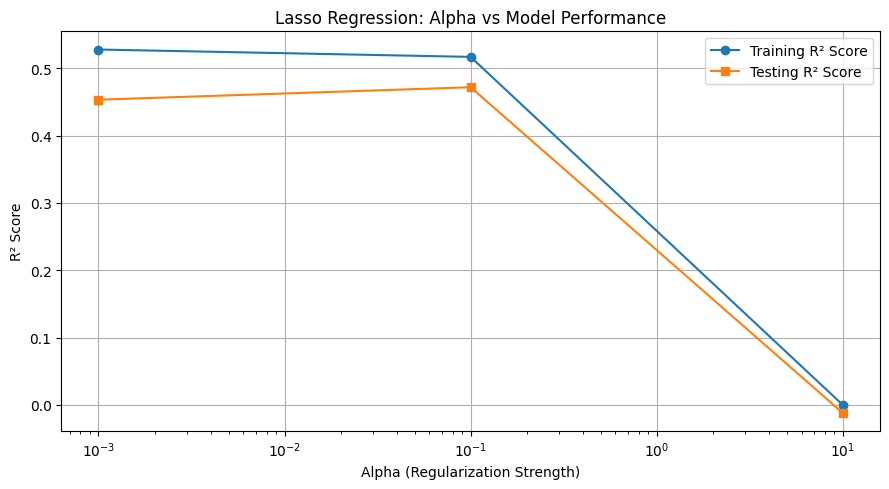

In [ ]:

import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

# Load dataset
X, y = load_diabetes(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

alphas = [0.001, 0.1, 10]

train_scores = []
test_scores = []

for a in alphas:
    model = Lasso(alpha=a, max_iter=10000)
    model.fit(X_train, y_train)

    train_score = model.score(X_train, y_train)
    test_score = model.score(X_test, y_test)

    train_scores.append(train_score)
    test_scores.append(test_score)

    print(f"Alpha = {a}")
    print("Train Score:", round(train_score, 3))
    print("Test Score :", round(test_score, 3))
    print()

# Visualization
plt.figure(figsize=(9, 5))

plt.plot(alphas, train_scores, marker='o',
         label='Training R² Score')

plt.plot(alphas, test_scores, marker='s',
         label='Testing R² Score')

plt.xscale('log')
plt.xlabel('Alpha (Regularization Strength)')
plt.ylabel('R² Score')
plt.title('Lasso Regression: Alpha vs Model Performance')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()




Alpha = 0
Training R2 Score: 0.5279
Testing R2 Score : 0.4526
Sum of Squared Coefficients: 2258034.01

Alpha = 0.001
Training R2 Score: 0.5278
Testing R2 Score : 0.4534
Sum of Squared Coefficients: 1920701.13

Alpha = 1
Training R2 Score: 0.4424
Testing R2 Score : 0.4192
Sum of Squared Coefficients: 233916.69

Alpha = 100
Training R2 Score: 0.0223
Testing R2 Score : 0.0122
Sum of Squared Coefficients: 236.07

Alpha = 10000
Training R2 Score: 0.0002
Testing R2 Score : -0.0117
Sum of Squared Coefficients: 0.02


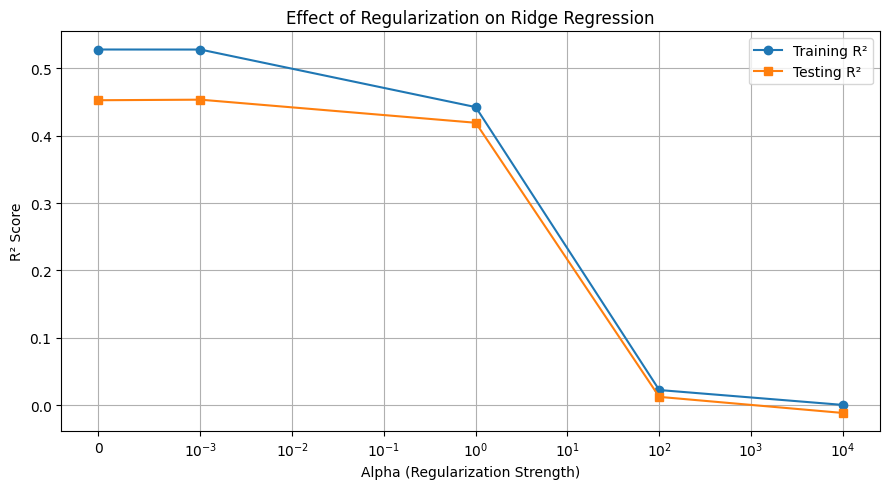

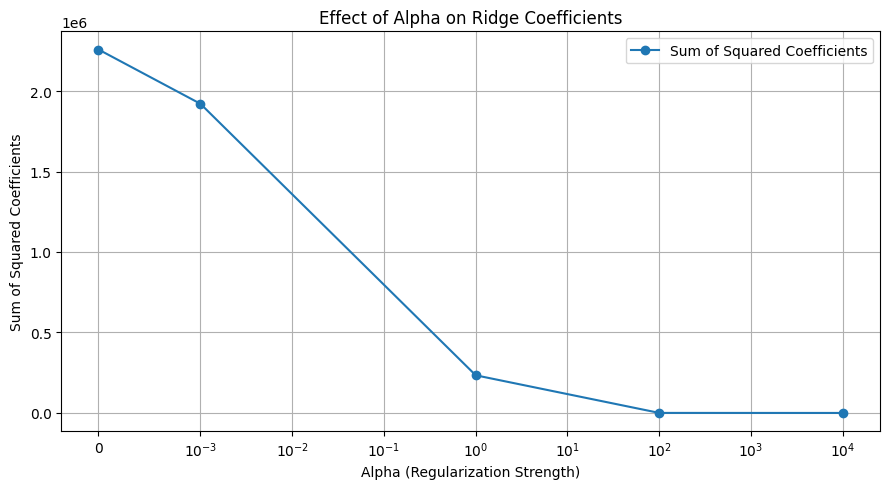

In [ ]:

from sklearn.linear_model import Ridge
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Load dataset
X, y = load_diabetes(return_X_y=True)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Different regularization strengths
alphas = [0, 0.001, 1, 100, 10000]

train_scores = []
test_scores = []
coefficient_sizes = []

for a in alphas:

    # Create Ridge model
    model = Ridge(alpha=a)

    # Train model
    model.fit(X_train, y_train)

    # Evaluate model
    train_score = model.score(X_train, y_train)
    test_score = model.score(X_test, y_test)

    # Sum of squared coefficients
    coef_size = sum(model.coef_ ** 2)

    train_scores.append(train_score)
    test_scores.append(test_score)
    coefficient_sizes.append(coef_size)

    print(f"\nAlpha = {a}")
    print("Training R2 Score:", round(train_score, 4))
    print("Testing R2 Score :", round(test_score, 4))
    print("Sum of Squared Coefficients:", round(coef_size, 2))

# Visualize model performance
plt.figure(figsize=(9, 5))

plt.plot(
    alphas, train_scores,
    marker='o', label='Training R²'
)

plt.plot(
    alphas, test_scores,
    marker='s', label='Testing R²'
)

plt.xscale('symlog', linthresh=0.001)
plt.xlabel('Alpha (Regularization Strength)')
plt.ylabel('R² Score')
plt.title('Effect of Regularization on Ridge Regression')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Visualize coefficient shrinkage
plt.figure(figsize=(9, 5))

plt.plot(
    alphas, coefficient_sizes,
    marker='o', label='Sum of Squared Coefficients'
)

plt.xscale('symlog', linthresh=0.001)
plt.xlabel('Alpha (Regularization Strength)')
plt.ylabel('Sum of Squared Coefficients')
plt.title('Effect of Alpha on Ridge Coefficients')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()




Input Shape: (943, 24, 1)
Output Shape: (943,)

Training Samples: 754
Testing Samples: 189


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_2 (GRU)                     │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - loss: 0.0733 - val_loss: 0.0022
Epoch 2/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0320 - val_loss: 0.0073
Epoch 3/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0220 - val_loss: 0.0029
Epoch 4/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0183 - val_loss: 0.0018
Epoch 5/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0145 - val_loss: 0.0010
Epoch 6/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0118 - val_loss: 4.3105e-04
Epoch 7/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0104 - val_loss: 2.3340e-04
Epoch 8/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0098 - val_loss: 1.7212e-04
Epoch 9/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0094 - val_loss: 1.5928e-04
Epoch 10/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0091 - val_loss: 1.5101e-04
Epoch 11/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0088 - val_loss: 1.4281e-04
Epoch 12/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 


First 10 Predictions:
Actual: 24.20 °C | Predicted: 24.12 °C
Actual: 24.30 °C | Predicted: 24.18 °C
Actual: 24.30 °C | Predicted: 24.26 °C
Actual: 24.30 °C | Predicted: 24.30 °C
Actual: 24.20 °C | Predicted: 24.32 °C
Actual: 24.20 °C | Predicted: 24.27 °C
Actual: 24.10 °C | Predicted: 24.24 °C
Actual: 24.10 °C | Predicted: 24.17 °C
Actual: 24.30 °C | Predicted: 24.13 °C
Actual: 24.40 °C | Predicted: 24.22 °C

Model Evaluation:
MAE:  0.21 °C
RMSE: 0.36 °C


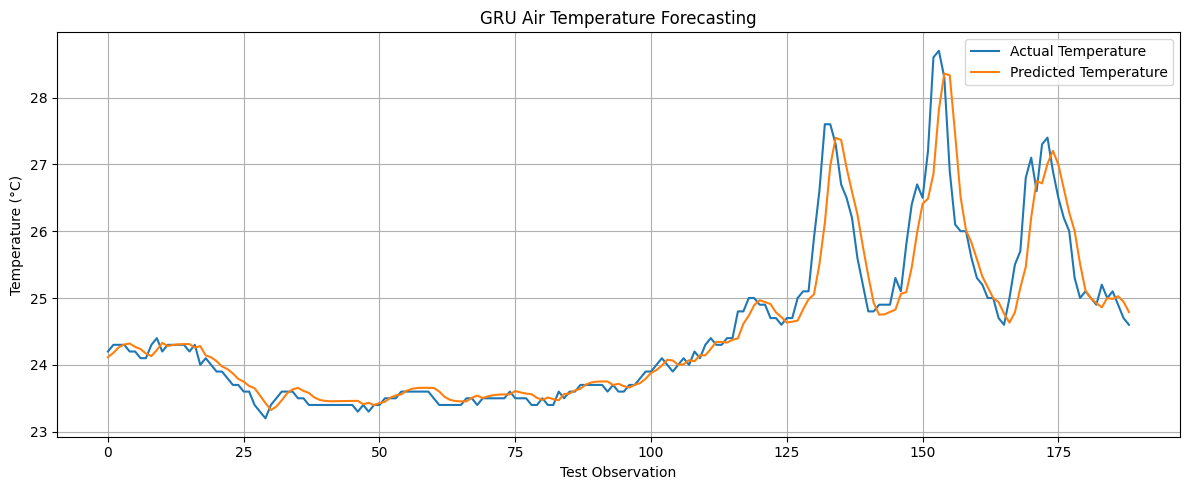


Predicted Next Temperature: 24.66 °C


In [ ]:


# GRU requires 3D input:
# (samples, timesteps, features)

X = X.reshape(X.shape[0], X.shape[1], 1)

print("\nInput Shape:", X.shape)
print("Output Shape:", y.shape)


# ==========================================
# 8. Split Training and Testing Data
# ==========================================

# Preserve chronological order.
split_index = int(len(X) * 0.80)

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


# ==========================================
# 9. Build GRU Model
# ==========================================

model = Sequential([
    Input(shape=(timesteps, 1)),
    GRU(32, activation="tanh"),
    Dense(1)
])

model.summary()


# ==========================================
# 10. Compile Model
# ==========================================

model.compile(
    optimizer="adam",
    loss="mse"
)


# ==========================================
# 11. Train Model
# ==========================================

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)


# ==========================================
# 12. Predict Test Temperatures
# ==========================================

predictions = model.predict(X_test, verbose=0)

# Convert scaled values back to Celsius
predicted_temp = scaler.inverse_transform(predictions)

actual_temp = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

print("\nFirst 10 Predictions:")

for actual, predicted in zip(
    actual_temp[:10].flatten(),
    predicted_temp[:10].flatten()
):
    print(
        f"Actual: {actual:.2f} °C | "
        f"Predicted: {predicted:.2f} °C"
    )


# ==========================================
# 13. Evaluate Model
# ==========================================

mae = mean_absolute_error(
    actual_temp,
    predicted_temp
)

rmse = np.sqrt(
    mean_squared_error(actual_temp, predicted_temp)
)

print("\nModel Evaluation:")
print(f"MAE:  {mae:.2f} °C")
print(f"RMSE: {rmse:.2f} °C")


# ==========================================
# 14. Plot Actual vs Predicted Temperature
# ==========================================

plt.figure(figsize=(12, 5))

plt.plot(
    actual_temp,
    label="Actual Temperature"
)

plt.plot(
    predicted_temp,
    label="Predicted Temperature"
)

plt.title("GRU Air Temperature Forecasting")
plt.xlabel("Test Observation")
plt.ylabel("Temperature (°C)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==========================================
# 15. Predict Next Temperature
# ==========================================

last_sequence = scaled_data[-timesteps:]

last_sequence = last_sequence.reshape(
    1, timesteps, 1
)

next_scaled = model.predict(
    last_sequence,
    verbose=0
)

next_temperature = scaler.inverse_transform(
    next_scaled
)

print(
    "\nPredicted Next Temperature:",
    round(float(next_temperature[0, 0]), 2),
    "°C"
)